Dataset shape: (150, 4)
Class distribution:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
\nFeatures: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
\nComparative performance (test set):
                      Accuracy  Macro Precision  Macro Recall  Macro F1-score  \
Model                                                                           
SVM                     0.9667           0.9697        0.9667          0.9666   
Decision Tree           0.9333           0.9333        0.9333          0.9333   
KNN (k=5)               0.9333           0.9444        0.9333          0.9327   
Gaussian Naive Bayes    0.9667           0.9697        0.9667          0.9666   

                      Log Loss  
Model                           
SVM                     0.1125  
Decision Tree           2.4029  
KNN (k=5)               0.1196  
Gaussian Naiv

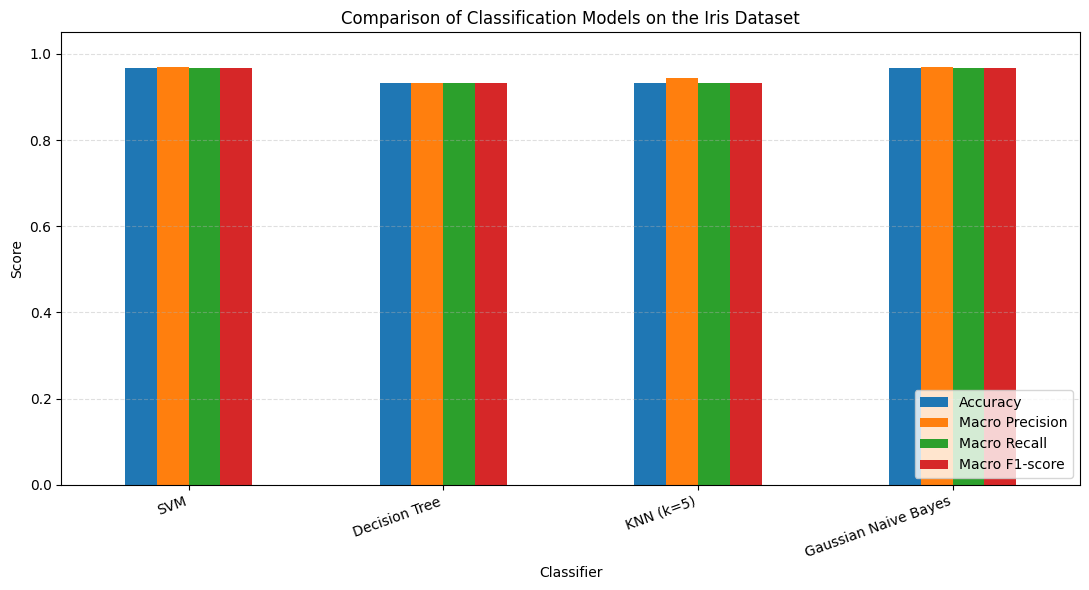

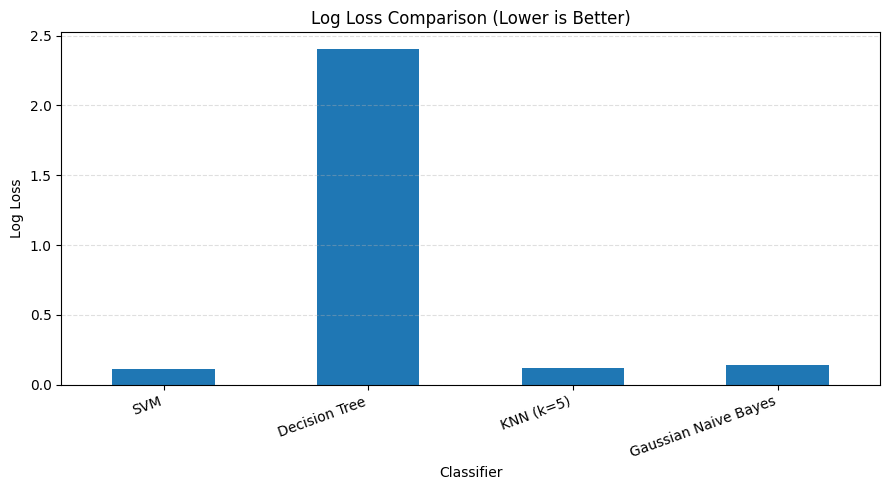

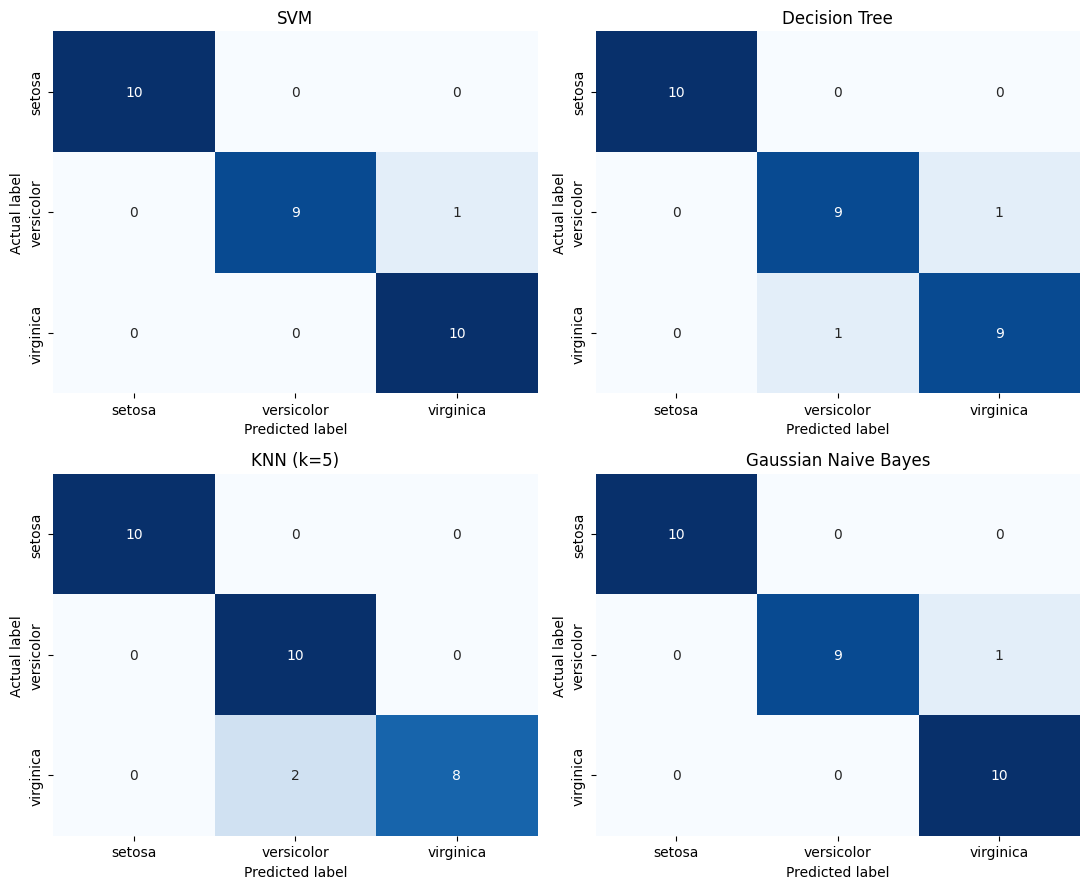

\nHighest test accuracy: SVM (0.9667)
Lowest log loss: SVM (0.1125)
\nExample new flower: {'sepal length (cm)': 5.1, 'sepal width (cm)': 3.5, 'petal length (cm)': 1.4, 'petal width (cm)': 0.2}
SVM predicted class: setosa


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, classification_report
)

# 1. Load the built-in Iris dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
class_names = list(iris.target_names)

print("Dataset shape:", X.shape)
print("Class distribution:")
print(y.map(dict(enumerate(class_names))).value_counts())
print("\\nFeatures:", list(X.columns))
print("Classes:", class_names)

# 2. Split data into training (80%) and testing (20%) sets.
# Stratification preserves the class proportions in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Define the four classification models.
# Scaling is included in pipelines for SVM and KNN because these models
# are sensitive to feature magnitudes. The scaler is fitted only on training data.
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", probability=True, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN (k=5)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Gaussian Naive Bayes": GaussianNB()
}

# 4. Train models, predict test labels, and calculate evaluation metrics.
rows = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    fitted_models[name] = model
    predictions[name] = y_pred

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1, 2])
    })

results_df = pd.DataFrame(rows).set_index("Model")
print("\\nComparative performance (test set):")
print(results_df.round(4))

# 5. Confusion matrices and detailed classification reports.
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
    print(f"\\n{name} — Confusion Matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(cm, index=class_names, columns=class_names))
    print(f"\\n{name} — Classification Report:")
    print(classification_report(
        y_test, y_pred, target_names=class_names, zero_division=0
    ))

# 6. Plot the metric comparison.
metrics_to_plot = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]
results_df[metrics_to_plot].plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Comparison of Classification Models on the Iris Dataset")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 7. Plot log loss separately (lower is better).
results_df["Log Loss"].plot(kind="bar", figsize=(9, 5))
plt.title("Log Loss Comparison (Lower is Better)")
plt.ylabel("Log Loss")
plt.xlabel("Classifier")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 8. Confusion matrix heatmaps.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    sns.heatmap(
        confusion_matrix(y_test, y_pred, labels=[0, 1, 2]),
        annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=class_names, yticklabels=class_names
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

# 9. Display the best model according to accuracy and the lowest log loss.
best_accuracy_model = results_df["Accuracy"].idxmax()
lowest_loss_model = results_df["Log Loss"].idxmin()
print("\\nHighest test accuracy:", best_accuracy_model,
      f"({results_df.loc[best_accuracy_model, 'Accuracy']:.4f})")
print("Lowest log loss:", lowest_loss_model,
      f"({results_df.loc[lowest_loss_model, 'Log Loss']:.4f})")

# Optional: classify a new flower measurement.
# Order: sepal length, sepal width, petal length, petal width (cm).
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
chosen_model = fitted_models["SVM"]
predicted_class = chosen_model.predict(new_flower)[0]
print("\\nExample new flower:", new_flower.iloc[0].to_dict())
print("SVM predicted class:", class_names[predicted_class])
